# 图 7-1　十八世纪古物学家的出生—死亡流动网络

按 Schich et al. (2014) *Science* 345:558–562 **图 1D** 的样式重绘，对应书稿第七章图 7-1。

**数据**
- 流量：论文随文外部数据库 S4（`schichdatas4_wcen.xlsx`），出生地 → 死亡地，含人次 `n`；
- 坐标：`fig1d_cities.csv`（`city / B / D / tot / z / lat / lon`，191 城，本图用坐标齐备的 190 城）。

**图的读法**
- 节点：城市，面积 ∝ 生卒合计人次 `tot`；颜色按 `z = (D − B)/√(D + B)` 判定，`z > 0.15` 红（死亡吸引地），`z < −0.15` 蓝（出生来源地），其余灰；
- 边：灰弧线，箭头指向死亡地，线宽与箭头大小 ∝ 人次；生卒同城者画成绕城的椭圆环；
- 白底、无底图，经纬度按 48°N 的余弦拉伸（`aspect = 1/cos 48°`），避免高纬变形。

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, Ellipse

HERE = Path.cwd()
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

# 中文字体：直接指定字体族（用 sans-serif 别名时部分文字会静默丢失）
plt.rcParams["font.family"] = ["Microsoft YaHei"]#, "SimHei", "SimSun", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("matplotlib", matplotlib.__version__, "| 工作目录", HERE)

matplotlib 3.4.3 | 工作目录 /Users/socrates/同步空间/Research/结构建模书稿章节/output/schich-repro


## 解决Matplotlib绘图显示中文问题
https://chengjun.github.io/mybook/0-matplotlib-chinese.html

In [2]:
print(matplotlib.matplotlib_fname())
print(matplotlib.get_cachedir())


/Users/socrates/opt/anaconda3/lib/python3.9/site-packages/matplotlib/mpl-data/matplotlibrc
/Users/socrates/.matplotlib


In [3]:
# ---------- 1. 数据：流量与坐标 ----------
w = pd.read_excel(HERE / "schichdatas4_wcen.xlsx")
w.columns = ["BLocID", "BLocLabel", "DLocID", "DLocLabel", "n"]

city = pd.read_csv(HERE / "fig1d_cities.csv").set_index("city")
coords = {c: (r.lon, r.lat) for c, r in city.iterrows()}

w["b_xy"] = w.BLocLabel.map(coords)
w["d_xy"] = w.DLocLabel.map(coords)
miss = w[w.b_xy.isna() | w.d_xy.isna()]
print("缺坐标城市:", set(miss.BLocLabel) | set(miss.DLocLabel))
w = w.dropna(subset=["b_xy", "d_xy"])

pairs = w[w.BLocLabel != w.DLocLabel]      # 城际流
loops = w[w.BLocLabel == w.DLocLabel]      # 自环（生卒同城）
print(f"城际 {len(pairs)} 条 / {int(pairs.n.sum())} 人次；"
      f"自环 {len(loops)} 条 / {int(loops.n.sum())} 人次；坐标齐备城市 {len(city)} 座")

缺坐标城市: {'St. Helena', 'Ajaccio'}
城际 171 条 / 190 人次；自环 28 条 / 89 人次；坐标齐备城市 190 座


In [4]:
# ---------- 2. 节点样式：面积 ∝ 生卒合计，颜色按 z ----------
C_RED, C_BLUE, C_EDGE = "#C1272D", "#1F4E9C", "#8A8A8A"

sz = 12 + 1450 * (city.tot / city.tot.max()) ** 1.10
colors = np.where(city.z > 0.15, C_RED, np.where(city.z < -0.15, C_BLUE, "#9A9A9A"))
node_pts = dict(zip(city.index, np.sqrt(sz) / 2))   # 供箭头收缩用（点半径）

print(f"红（死亡吸引地）{int((city.z > 0.15).sum())} 座 | "
      f"蓝（出生来源地）{int((city.z < -0.15).sum())} 座 | "
      f"灰 {int(((city.z >= -0.15) & (city.z <= 0.15)).sum())} 座")
print(f"最大城市 {city.tot.idxmax()}（{city.tot.max():.0f} 人次）")

红（死亡吸引地）46 座 | 蓝（出生来源地）125 座 | 灰 19 座
最大城市 Roma（109 人次）


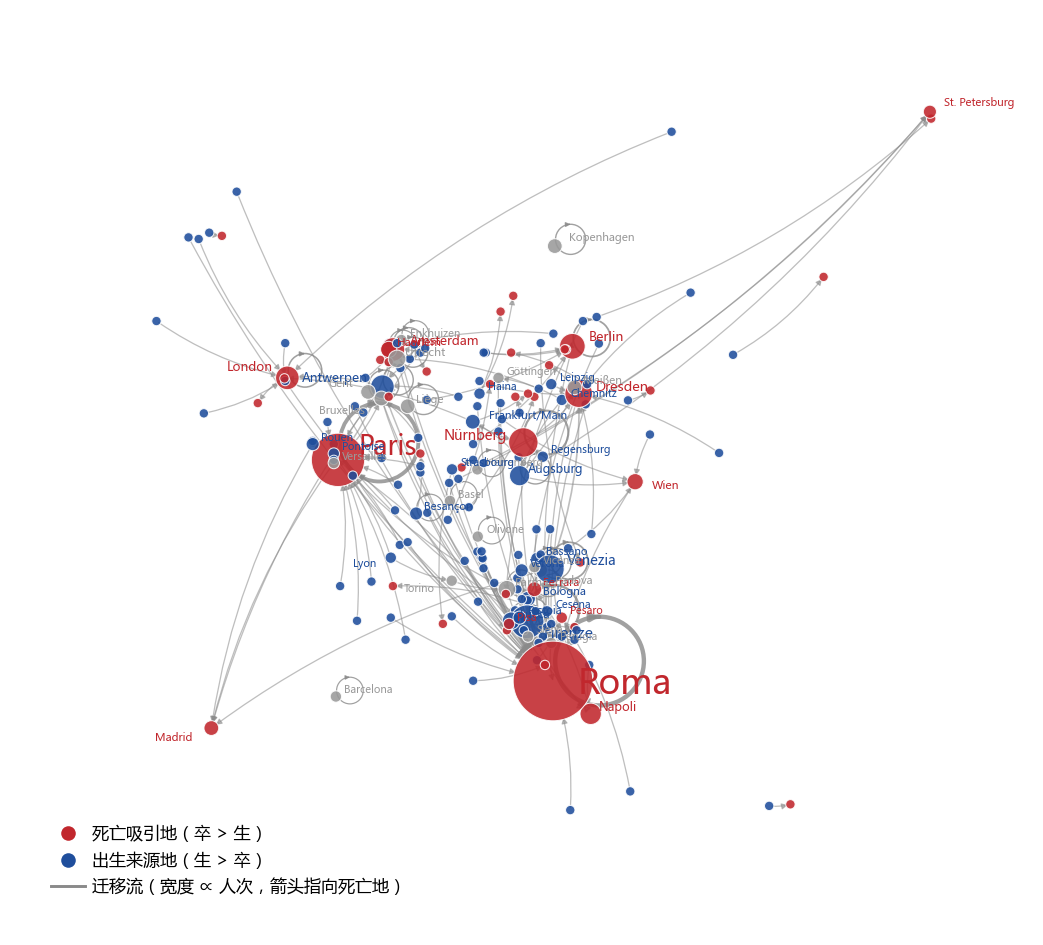

In [8]:
# ---------- 3. 绘图 ----------
fig, ax = plt.subplots(figsize=(8.6, 6.4), dpi=150)
ax.set_facecolor("white")
ASP = 1 / np.cos(np.radians(48))     # 48°N 的经度压缩

# 3.1 迁移弧线：出生 → 死亡
for _, r in pairs.iterrows():
    (x1, y1), (x2, y2) = r.b_xy, r.d_xy
    if np.hypot(x2 - x1, y2 - y1) == 0:
        continue
    lw = 0.35 + 1.15 * np.sqrt(r.n / w.n.max())
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2), connectionstyle="arc3,rad=0.10",
        arrowstyle="-|>", mutation_scale=4.5 + 6.0 * np.sqrt(r.n / w.n.max()),
        lw=lw, color=C_EDGE, alpha=0.55, zorder=1,
        shrinkA=max(0, node_pts.get(r.BLocLabel, 2) - 1),
        shrinkB=max(0, node_pts.get(r.DLocLabel, 2) - 1), capstyle="round"))

# 3.2 自环：椭圆环 + 箭头（生卒同城）
for _, r in loops.iterrows():
    cx, cy = r.d_xy
    rr = 0.55 + 1.55 * (r.n / w.n.max())
    h = rr / ASP
    cx0, cy0 = cx + 1.05 * rr, cy + 0.30 * rr
    ax.add_patch(Ellipse((cx0, cy0), width=2 * rr, height=2 * h, fill=False,
                         edgecolor=C_EDGE, lw=0.5 + 1.6 * r.n / w.n.max(), alpha=0.8, zorder=2))
    th = np.pi / 2
    ax.annotate("", xy=(cx0 + rr * np.cos(th), cy0 + h * np.sin(th)),
                xytext=(cx0 + rr * np.cos(th + 0.10), cy0 + h * np.sin(th + 0.10)),
                arrowprops=dict(arrowstyle="-|>", color=C_EDGE,
                                lw=0.5 + 1.6 * r.n / w.n.max(), alpha=0.8,
                                mutation_scale=4 + 3 * r.n / w.n.max()), zorder=2)

# 3.3 节点
ax.scatter(city.lon, city.lat, s=sz, c=colors, alpha=0.88,
           edgecolors="white", linewidths=0.5, zorder=3)

# 3.4 标签：字号 ∝ 城市规模，只标 tot ≥ 2 的城市
fs = dict(zip(city.index, 4.6 + 8.8 * (city.tot / city.tot.max()) ** 0.8))
fs["Roma"], fs["Paris"] = 16.5, 12.5
OFFS = {"Roma": (12, -2), "Paris": (10, 6), "London": (-7, 5), "Amsterdam": (8, 4),
        "Berlin": (8, 4), "Wien": (8, -2), "Firenze": (8, -6), "Venezia": (8, 4),
        "Madrid": (-9, -5), "Frankfurt/Main": (8, 3), "Nürnberg": (-8, 3),
        "St. Petersburg": (7, 4), "Kopenhagen": (7, 4), "München": (7, -7),
        "Antwerpen": (-7, 4), "Bruxelles": (-8, -6), "Den Haag": (-7, 4),
        "Torino": (-8, -4), "Stockholm": (6, 4), "Warschau": (7, 4), "Gent": (-7, 4),
        "Padova": (7, -5), "Genova": (-8, -5), "Bologna": (7, 3), "Dresden": (8, 3),
        "Stettin": (6, 3), "Breslau": (6, -3), "Prag": (7, 3), "Lyon": (-7, -3),
        "Lissabon": (-7, -3), "Neapel": (7, 3)}
for c, r in city[city.tot >= 2].iterrows():
    dx, dy = OFFS.get(c, (4, 3))
    ax.annotate(c, (r.lon, r.lat), xytext=(dx, dy), textcoords="offset points",
                fontsize=fs.get(c, 5.5), color=colors[list(city.index).index(c)],
                ha="right" if dx < 0 else "left", va="center", zorder=4)

# 3.5 图例与图内标题
handles = [Line2D([], [], marker="o", ls="", mfc=C_RED, mec="white", ms=8, label="死亡吸引地（卒 > 生）"),
           Line2D([], [], marker="o", ls="", mfc=C_BLUE, mec="white", ms=8, label="出生来源地（生 > 卒）"),
           Line2D([], [], color=C_EDGE, lw=1.4, label="迁移流（宽度 ∝ 人次，箭头指向死亡地）")]
ax.legend(handles=handles, frameon=False, fontsize=8.2, loc="lower left",
          bbox_to_anchor=(0.02, 0.02), handletextpad=0.4)


ax.set_xlim(-13, 35)
ax.set_ylim(34, 63)
ax.set_aspect(ASP)
ax.set_axis_off()
fig.tight_layout()
#plt.show()

In [6]:
# ---------- 4. 保存 ----------
out1 = FIG / "fig7_1_network_notebook.pdf"
fig.savefig(out1, facecolor="white", bbox_inches="tight")
print("已保存", out1.name, f"({out1.stat().st_size / 1024:.0f} KB)")

已保存 fig7_1_network_notebook.pdf (84 KB)


## 读图要点

1. **一城独大不是视觉夸张**：罗马节点最大（生卒合计 109 人次），且几乎所有的线都指向它；节点面积按 `tot` 缩放，读者看到的大小差别就是人次差别。
2. **红的不是“大城市”，是“净吸纳地”**：颜色由 `z`（相对不平衡）决定，与规模无关。巴黎、罗马既大又红；一些小城同样红，说明磁力不等于体量。
3. **自环要单独交代**：生卒同城的 28 条自环画成绕城小环，它们在图上有形、在密度计算中按惯例剔除——“呈现”与“计算”两套口径必须说明（正文即以此为例）。
4. **箭头方向即人才流向**：绝大多数边朝意大利半岛汇聚，反方向的极少；这正是正文所说“最大强组件只有 8 座城市”的视觉依据。